# Financial Opportunity Copilot — Demo Walkthrough

This notebook walks through the pipeline end to end: real customer profiles →
synthetic account/transaction overlay → SQL feature engineering → six
opportunity-detection models → an agentic layer that turns flagged
opportunities into a prioritized, plain-English brief.

Run `python -m src.pipeline build-data && python -m src.pipeline build-features \
&& python -m src.pipeline train` from the project root before this notebook —
it reads the generated CSVs, the trained models, and the diagnostic figures
rather than recomputing them.

In [1]:
import json
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

sys.path.insert(0, str(Path.cwd().parent))
from src.config import DATA_PROCESSED, FIGURES_DIR, REPORTS_DIR

pd.set_option("display.max_columns", 20)


## 1. The data: one real anchor, one synthetic overlay

`customers.csv` comes straight from the UCI Bank Marketing dataset (41,188 real bank customers: age, job, marital status, education, existing loan flags). No public dataset carries account balances, 401k contributions, or brokerage holdings for these customers, so `generate_synthetic.py` synthesizes that overlay for a 5,000-customer sample, keyed by `customer_id`.

In [2]:
customers = pd.read_csv(DATA_PROCESSED / "customers.csv")
sample = pd.read_csv(DATA_PROCESSED / "customers_sample.csv")
print(f"Real UCI profiles: {len(customers):,}")
print(f"Synthetic-overlay sample: {len(sample):,}")
sample[["age", "job", "est_annual_income", "marginal_tax_rate"]].describe(include="all").T


Real UCI profiles: 41,188
Synthetic-overlay sample: 5,000


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,5000.0,NaN,NaN,NaN,39.7984,10.336805,17.0,32.0,38.0,46.0,92.0
job,5000,12,admin.,1246,NaN,NaN,NaN,NaN,NaN,NaN,NaN
est_annual_income,5000.0,NaN,NaN,NaN,60835.38,30426.395175,12000.0,40800.0,54100.0,73325.0,222600.0
marginal_tax_rate,5000.0,NaN,NaN,NaN,0.181312,0.051025,0.12,0.12,0.22,0.22,0.32


## 2. Feature table (SQL-derived)

`src/features/queries.sql` aggregates 360k transaction rows and brokerage holdings down to one row per customer — monthly spend by category, a window-function subscription-growth trend, and unrealized gain/loss — which `build_features.py` joins onto the account/profile tables.

In [3]:
features = pd.read_csv(DATA_PROCESSED / "feature_table.csv")
print(f"{features.shape[0]:,} customers x {features.shape[1]} features")
features[["savings_balance", "avg_monthly_spend", "emergency_fund_months",
          "avg_subscription_mom_growth", "harvestable_loss"]].describe().T


5,000 customers x 40 features


,count,mean,std,min,25%,50%,75%,max
savings_balance,5000.0,9166.714456,12478.313247,65.450000,2755.590000,5398.795000,10729.170000,204116.290000
avg_monthly_spend,5000.0,2286.713420,1187.807676,351.775000,1506.641458,2007.263333,2788.398542,9000.820000
emergency_fund_months,5000.0,4.095672,4.866498,0.045440,1.458023,2.651890,4.949599,126.216309
avg_subscription_mom_growth,5000.0,0.013435,0.018398,-0.032995,0.000828,0.009178,0.021997,0.088363
harvestable_loss,5000.0,133.905810,489.900250,0.000000,0.000000,0.000000,0.000000,7015.540000


## 3. Model diagnostics

Six opportunity types, each trained on a feature snapshot with realistic noise and missingness injected (simulating a T-1 batch feed) rather than the exact clean inputs the labeling rule uses — see `simulate_snapshot_noise` in `src/features/heuristic_labels.py`.

In [4]:
metrics = json.loads((REPORTS_DIR / "metrics.json").read_text())
rows = []
for m in metrics:
    best = m["metrics"][m["best_model"]]
    rows.append({"label": m["label"], "best_model": m["best_model"], "base_rate": m["base_rate"], **best})
pd.DataFrame(rows).set_index("label").sort_values("pr_auc", ascending=False)


,best_model,base_rate,roc_auc,pr_auc,brier
label,,,,,
opp_retirement_gap,hist_gradient_boosting,0.4006,1.0000,1.0000,0.0000
opp_high_interest_debt,logistic_regression,0.6502,1.0000,1.0000,0.0000
opp_tax_loss_harvest,hist_gradient_boosting,0.0790,0.9978,0.9792,0.0102
opp_emergency_fund_gap,hist_gradient_boosting,0.5562,0.9459,0.9550,0.0946
opp_high_yield_savings,hist_gradient_boosting,0.4032,0.9513,0.9385,0.0882
opp_subscription_creep,hist_gradient_boosting,0.1828,0.9688,0.9044,0.0553


**Reading these results honestly:** `opp_retirement_gap` and `opp_high_interest_debt` "
"hit ~1.00 AUC because their rules key off account *metadata* (contribution rate vs. "
"employer match cap; card APR) that a bank always knows exactly — there's no "
"staleness to model, so this is really a rule lookup, not a learned pattern. "
"`opp_high_yield_savings`, `opp_emergency_fund_gap`, `opp_tax_loss_harvest`, and "
"`opp_subscription_creep` key off noised balance/spend feeds and land in a much "
"more believable 0.90–0.99 PR-AUC range — strong, but earned under realistic "
"data staleness rather than a giveaway.

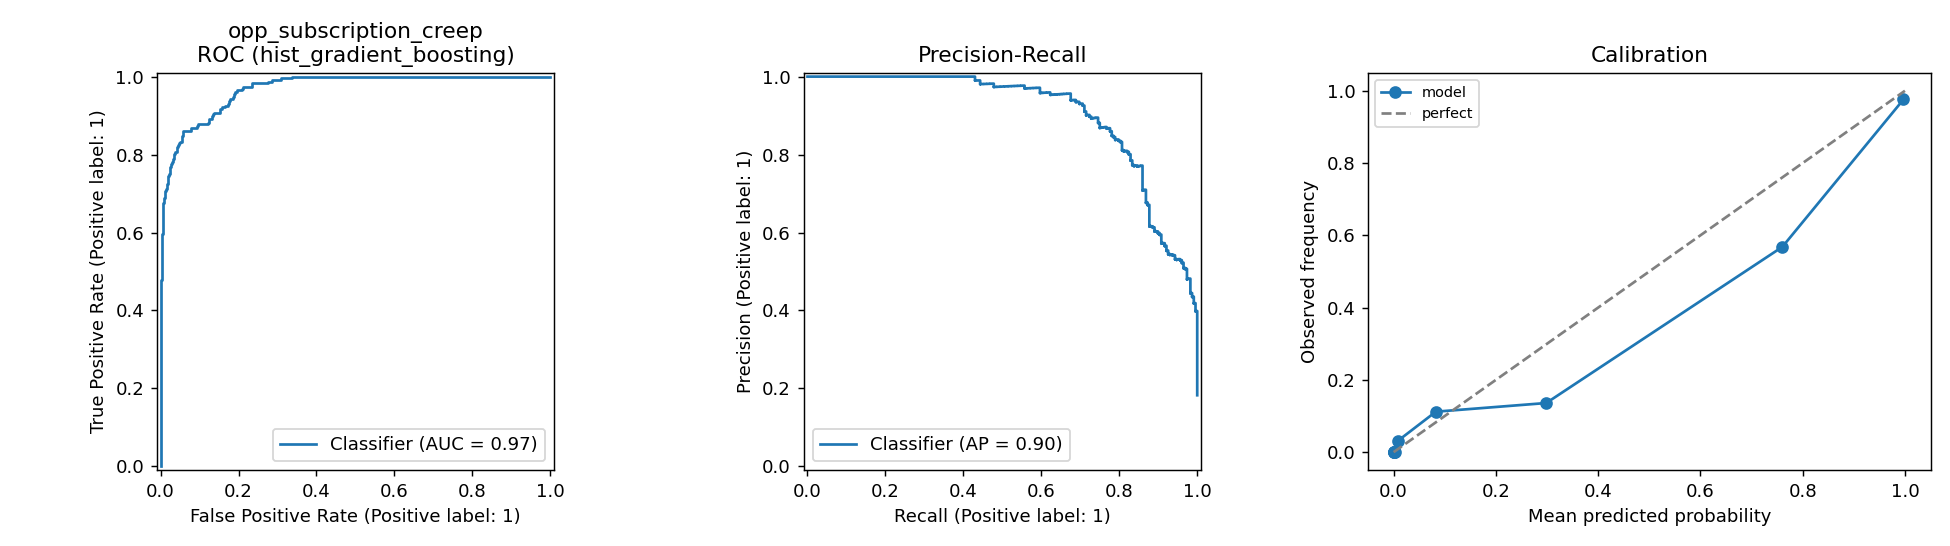

In [5]:
display(Image(filename=str(FIGURES_DIR / "opp_subscription_creep_diagnostics.png")))


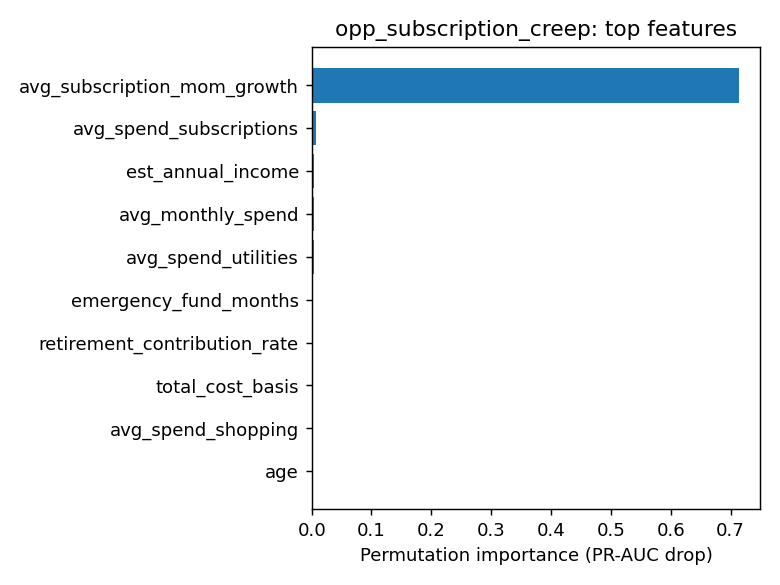

In [6]:
display(Image(filename=str(FIGURES_DIR / "opp_subscription_creep_importance.png")))


## 4. Scoring a customer

`score_customer` reproduces the same noised snapshot used at training time, runs all six models, and returns a ranked opportunity list.

In [7]:
from src.pipeline import score_customer

row, opportunities = score_customer(57)
pd.DataFrame(opportunities)


,label,probability,flagged
0,opp_retirement_gap,1.0000,True
1,opp_high_interest_debt,0.9993,True
2,opp_subscription_creep,0.9876,True
3,opp_high_yield_savings,0.8193,True
4,opp_emergency_fund_gap,0.5279,True
5,opp_tax_loss_harvest,0.0001,False


## 5. The agentic layer

`FinancialOpportunityAgent` (see `src/agent/copilot_agent.py`) takes the customer profile plus the flagged opportunities above and calls the Claude API with six deterministic financial-math tools (`src/agent/tools.py`). The model decides *what to prioritize and how to explain it*; every dollar figure it states has to come from a tool call, never its own arithmetic. Requires `ANTHROPIC_API_KEY` — run from the project root:

```bash
python -m src.pipeline brief --customer-id 57
```

This prints the prioritized brief, logs every tool call the model made for auditability, and saves the full transcript to `reports/briefs/customer_57.json`.

## Limitations

- Account balances, transactions, and holdings are **synthetic** — only the demographic anchor (age/job/marital/education/existing loans) is real.
- Opportunity labels are **heuristic weak supervision**, not observed customer outcomes; there is no public dataset of "did this customer act on a nudge."
- The agent is scoped to general financial-planning nudges and explicitly declines individualized investment or tax advice — see the system prompt in `src/agent/copilot_agent.py`.